### 工作進度  
* 【置頂】**筆記內容架構**與**量化技術分析系統**相關資訊請參閱[260531筆記.ipynb](https://github.com/yilintung/StockInvestmentNotebook/blob/main/260531%E7%AD%86%E8%A8%98.ipynb)之「工作進度」。  
* 雖然行情還沒翻多，不過本周觀察股已經比較可以挑了，所以大家......起床啦！  
  今晚看完[訂閱](https://campaign.businessweekly.com.tw/bw/949)，各位同學周末要開始做功課，不然下周突然發動，你會不知道買甚麼。  
* 開盤後電視記者連線，有一陣子會消失，大家自己加油，不過今天盤應該波動不大，但盤後工作和整理比較重要，今天應該會有些股表態了。  
  跟各位分享一下，剛剛採訪內容，我們實際上對話的摘要，可以比對一下，到時候被剪出來會剩下什麼樣的狀況XD ：  
  1. 選舉前國家隊進場護盤力道有多大? 力抗外資有成效嗎?   
     資金有限防守為主，市場信心增加大於買盤，但相對國際股市抗跌，台股波段跌幅相對小，關鍵還是國際股市有止穩  
  2. 外資為何要狂賣台積電?   
     AI估值過高適度調節+國際股市震盪  
  3. 瑤池金母信眾栽了？爆違約交割1.04億，甚麼狀況造成?  
     暴漲3千多，暴跌2千多，操作反應不及，多空都被殺  
  4. 台股選前今天行情?  
     外資感恩節放假，量能偏低，基本上指數還是在區間，有機會收紅，但漲點不大
* [國安基金護盤有效？選前大盤力拚收紅？](https://www.facebook.com/reel/2333326660851387)  
  📺 K線捕手 楊忠憲 老師  
  在第一時間接受三立iNEWS專訪解盤  
    
  **三立新聞採訪｜精簡版**   
  1. 選舉前國家隊進場護盤力道有多大？力抗外資有成效嗎？  
     國家隊資金有限，目前應以防守、穩定信心為主，心理面的效果大於實際買盤。台股近期相對國際股市抗跌，但真正要止穩，關鍵還是國際股市必須先回穩。  
  2. 外資為何要狂賣台積電？  
     主要是AI概念股估值偏高，外資適度獲利了結，加上國際股市震盪加劇，進行資金調節與風險控管，不見得代表看壞台積電長期基本面。  
  3. 瑤池金母信眾爆違約交割1.04億，什麼狀況造成？  
     近期台股暴漲3,000多點，又暴跌2,000多點，行情變化太快，投資人反應不及。尤其槓桿操作或追高殺低，很容易多空雙殺，也凸顯資金控管的重要性。  
  4. 台股選前今天行情如何看？  
     美國感恩節外資休假，預期量能偏低，指數仍以區間震盪看待，不排除收紅，但漲幅有限。短線關鍵還是觀察國際股市能否止穩。  

* 引入模組與定義公用函式  

In [ ]:
import numpy as np
import mysys
import markdown
from IPython.core.display import HTML

In [ ]:
def stock_analysis( analysis, stock_id, buttom_pattern = False) :
    results,images = analysis.analysis(stock_id)
    if results is not None :
        if buttom_pattern is True and '底部型態' in images :
            print('底型反轉交易策略：')
            display(images['底部型態'])
        print('解盤內容：')
        if '整體評價' in images and images['整體評價'] is not None  :
            display(images['整體評價'])
        result_md   = results.to_markdown(tablefmt="grid")
        result_html = markdown.markdown(result_md, extensions=['markdown_grid_tables:GridTableExtension'])
        display(HTML(result_html))

* 更新量化技術分析資料庫  

In [ ]:
mysys.UpdateStockDatabase()

* 建立「解盤」物件    

In [ ]:
analysis = mysys.StockAnalysis()

### 大盤解盤  

* 加權指數  

> **盤後**：量化技術分析  

In [ ]:
# 盤後：加權指數解盤
stock_analysis(analysis,'TAIEX')

* 櫃買指數  

> **盤後**：量化技術分析  

In [ ]:
# 盤後：櫃買指數解盤
stock_analysis(analysis,'TPEx')

### 個股篩選  

* 選股程序    

In [ ]:
results = analysis.screener()

In [ ]:
for stock_info in results :
    print('股票代碼 ＝ {} ， 股票名稱 ＝ {} '.format(stock_info[0],stock_info[1]))

* 篩選結果  
   - 宣德(5457)：技術突破  
     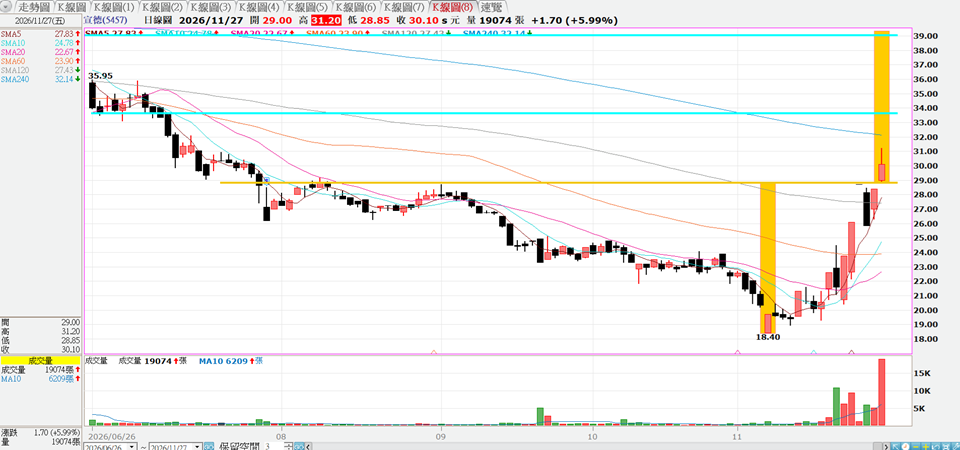  
   - 國產(2504)：？  
     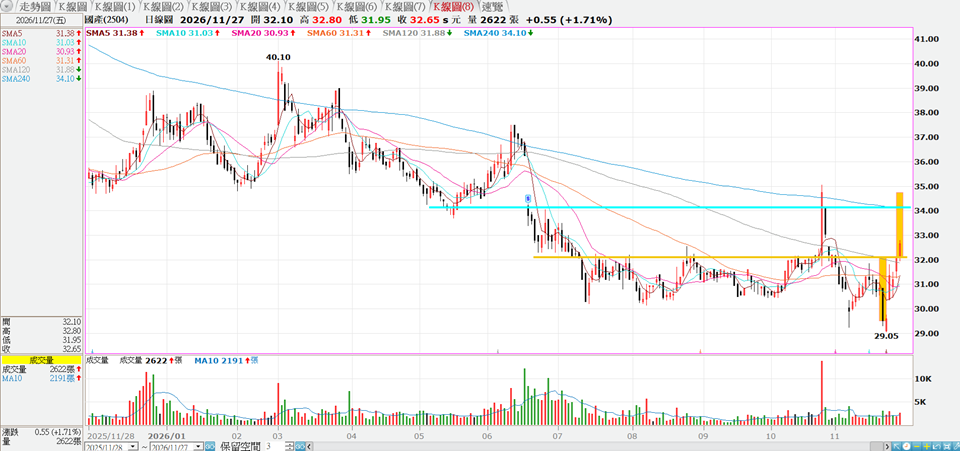  

* 觀察股列表  
  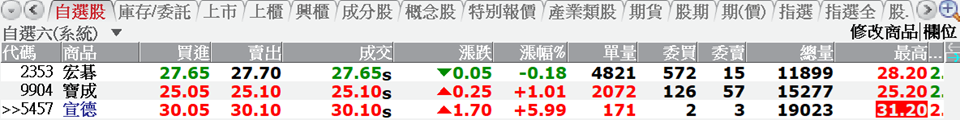   

### 個股解盤  

* 宣德(5457)  
  看法：底部型態有效突破第一天。  

> **盤後**：量化技術分析  

In [ ]:
stock_analysis(analysis,'5457')

> **盤後**：底部反轉交易策略分析  

In [ ]:
def line_drawing_callback( range_prices) :
    # 設定頸線
    neckline_start_date  = '2026-07-28'
    neckline_end_date   = range_prices.iloc[-1].name.strftime("%Y-%m-%d")
    neckline_price      = range_prices.loc['2026-08-10']['Close']

    # 設定底部日期與價格
    bottom_date           = '2026-11-06'
    bottom_price          = range_prices.loc['2026-11-06']['Open']

    # 估算目標價
    target_price = (neckline_price - bottom_price) + neckline_price

    print('估算目標價為{:.2f}元'.format(target_price))

    # 設定突破日期
    breakout_date = '2026-11-27'
    
    seq_of_seq_of_points=[
        [(neckline_start_date,neckline_price),(neckline_end_date,neckline_price)],
        [(bottom_date,bottom_price),(bottom_date,neckline_price)],
        [(breakout_date,neckline_price),(breakout_date,target_price)]
    ]

    linewidths=[2.0,15.0,15.0]
    
    colors=['xkcd:orange yellow','xkcd:orange yellow','xkcd:orange yellow']
    
    return seq_of_seq_of_points,linewidths,colors

In [ ]:
image = mysys.DrawOnKlineChart('5457','2026-06-15','2026-11-27',line_drawing_callback)
display(image)

籌碼面：  
法人○○( )：外資○○( )、投信○○( )、自營○○( )。  
主力○○( )。  
分公司買賣家數差○○( )。  
融資○○( )、融券○○( )。  